(lineage_recorders)=

# Lineage recorders

A lineage recorder writes heritable edits into target sites of the genome as cells divide, so the edits that cells share record their common ancestors, and tree builders reconstruct a phylogeny from them: a tree whose leaves are the sampled cells and whose internal nodes are their ancestors. Cutting the tree at a time groups the cells into clones, the descendants of each lineage alive at that time, and cell types that share clones descend from common ancestors.

This page follows one mouse embryo that @Colgan_2026 traced with PEtracer [@Koblan_2025], a recorder whose prime editor writes one of eight five-base insertions, the lineage marks, into the three sites of each of about 35 integrated copies of a target cassette. The embryo, collected at embryonic day 7.5 (E7.5), is a chimera: its donor cells descend from a few injected stem cells that carry the recorder, and its host cells carry none. The page builds an expression store, reads each cell's marks, imports the trees that the authors built from them, cuts the trees every half day from E5.0 to E7.0, and measures at each cut which cell types share clones.

## Download the embryo

GEO series [GSE342226](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE342226) holds embryo E7.5-R1 in two samples: GSM9925879, its expression matrix, and GSM9925880, its character matrix of each cell's marks and the two trees that the authors reconstructed. The authors also released the data under the MIT License as the Mouse Embryonic Lineage Atlas on [Zenodo](https://zenodo.org/records/23088914), with a table of their cell annotation. The table spans 16 embryos in 359 MB and starts with the donor cells of E7.5-R1, so download only its header and those rows, the first 185,933 bytes, with an HTTP range request. The downloads take 34 MB together.

The example uses a temporary directory. Use a project directory instead if you want to keep the downloaded files and the store after closing the notebook.

In [1]:
# Download and verify the published files.
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import Request, urlopen

# Summarize the results in tables.
import pandas as pd

# Analyze the embryo.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-06T15:53:17.725233Z | Wall time: 0.618 s

In [2]:
# Pin each file so that a changed download cannot alter the example silently,
# and name the files as the authors name the embryo and its clones.
geo = "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9925nnn"
sources = {
    "E7.5-R1_matrix.mtx.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_matrix.mtx.gz",
        "d246178e0c6e045b735ac36770ecdbe73cbbdc1628b2b48945f7050e959d33a8",
    ),
    "E7.5-R1_features.tsv.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_features.tsv.gz",
        "28ab91827cb07d8ba9071ebe98101ade7a0f7a3f8f7d48b28c8e1f807f062c70",
    ),
    "E7.5-R1_barcodes.tsv.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_barcodes.tsv.gz",
        "47d445ff2cf5944ab66dfda8f0db3d5e91690d29c086de0a7c0a957b3309de66",
    ),
    "E7.5-R1_characters.csv.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_characters.csv.gz",
        "166131c571ca30338435d25bd3f437512e44c79a5d428953fe72d04bb4385e85",
    ),
    "E7.5-R1-C1.nwk.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_E7.5-R1-C1.nwk.gz",
        "85e822845ca9774c9ca060375ea177f4b96a8b3994d00d297b1de15f6746714d",
    ),
    "E7.5-R1-C2.nwk.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_E7.5-R1-C2.nwk.gz",
        "37f008640400fcee2b15d2988ce64c856d1d0e017229fff71d86a125773b562d",
    ),
    "E7.5-R1_donor_cells.csv": (
        "https://zenodo.org/records/23088914/files/E7.5-E10_cells.csv",
        "f96960f5f78f2d15321ef6acf3eecb546a0dc1f3a8aa074472212a3c13a4e341",
    ),
}

# Read only the header and the donor rows of E7.5-R1 from the atlas's cell table.
byte_ranges = {"E7.5-R1_donor_cells.csv": "bytes=0-185932"}

paths = {}
for name, (url, expected_digest) in sources.items():
    path = output_dir / name

    # Copy the response in blocks without holding the file in memory, and
    # refuse a whole table sent in place of the bytes requested.
    headers = {"Range": byte_ranges[name]} if name in byte_ranges else {}
    with urlopen(Request(url, headers=headers), timeout=60) as response:
        if headers and response.status != 206:
            raise ValueError(f"{url} was sent whole, not the bytes requested")
        with path.open("wb") as target:
            shutil.copyfileobj(response, target)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(3)

E7.5-R1_matrix.mtx.gz        33.505
E7.5-R1_features.tsv.gz       0.637
E7.5-R1_barcodes.tsv.gz       0.008
E7.5-R1_characters.csv.gz     0.027
E7.5-R1-C1.nwk.gz             0.017
E7.5-R1-C2.nwk.gz             0.004
E7.5-R1_donor_cells.csv       0.186
Name: Downloaded MB, dtype: float64

Started: 2026-11-06T15:53:18.346701Z | Wall time: 4.076 s

## Build the expression store

The expression matrix counts 78,258 genes in the 1,342 cells that the authors kept, donor and host. `inspect_mtx` pairs the matrix with its gene and cell files, and `MtxToZarr` writes them into a new store.

In [3]:
# Pair the matrix with its gene and cell files, and write them into a new store.
(candidate,) = cytearc.inspect_mtx(str(paths["E7.5-R1_matrix.mtx.gz"]))
store_path = output_dir / "E7.5-R1.zarr"
cytearc.MtxToZarr(cytearc.MtxReader(candidate), zarr_loc=str(store_path)).dump()

# Open the store, with its RNA assay as the default.
ds = cytearc.DataStore(str(store_path), default_assay="RNA")
ds

DataStore has 1342 (1342) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo'
   RNA assay has 78258 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'nCells'

Started: 2026-11-06T15:53:22.424778Z | Wall time: 13.038 s

Label each donor cell with the authors' cell type and the other 310 cells, the host's, as `host`, in a cell column that later steps group cells by.

In [4]:
# Read the authors' annotation, and check that it names this embryo's donor cells.
annotation = pd.read_csv(paths["E7.5-R1_donor_cells.csv"], index_col=0)
cell_ids = pd.Index(ds.cells.fetch_all("ids"))
if not (
    annotation["embryo"].eq("E7.5-R1").all()
    and annotation["type"].eq("donor").all()
    and annotation.index.isin(cell_ids).all()
):
    raise ValueError("The annotation names cells outside this embryo's donor cells")

# Label each cell with its type, and the cells that the rows leave out as host.
cell_types = annotation["cell_type"].reindex(cell_ids, fill_value="host")
ds.cells.insert("cell_type", cell_types, overwrite=True)

# Count the cells of each type.
cell_types.value_counts().rename("Cells").rename_axis("Cell type").to_frame()

,Cells
Cell type,
Nascent mesoderm,325
host,310
Rostral ectoderm,215
Epiblast,175
Extraembryonic mesoderm,134
Primitive streak,91
Definitive endoderm,39
Hematoendothelial progenitor,32
Notochord,17


Started: 2026-11-06T15:53:35.474543Z | Wall time: 0.047 s

Place the cell types on a UMAP with the RNA recipe. The authors' quality control already kept these cells, so `filtering=False` analyzes all of them.

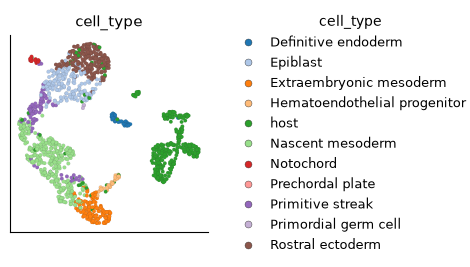

Started: 2026-11-06T15:53:35.524939Z | Wall time: 137.870 s

In [5]:
# Embed every cell with the RNA recipe, keeping the cells that the authors kept.
run = ds.pipeline.rna(label="rna", filtering=False)

# Locate the cell types on the UMAP.
ds.plots.embedding(layout=run["umap"], color_by="cell_type")

The donor cells spread from the epiblast to the rostral ectoderm on one side and through the primitive streak to the mesoderm on the other, while most host cells gather in a group of their own.

## Read the character matrix

PEtracer's character matrix holds one row per cell and one column per site, named by its integration, one copy of the cassette, and its site, such as `intID250-EMX1`. An entry is `*` for an unedited site, `1` to `8` for a lineage mark, `!` for another insertion and `-` for a site that was not read. `clones.import_alleles` recognizes the format and joins each row to the cell of the same ID.

In [6]:
# Read the marks of every cell.
cells = ds.snapshot_cell_selection("I")
alleles = ds.clones.import_alleles(
    paths["E7.5-R1_characters.csv.gz"], cell_selection=cells
)

# Compare the donor and host cells by the integrations read and the sites edited.
allele_cells = ds.clones.load_alleles(alleles).cells[["n_integrations", "n_edits"]]
origin = cell_types.eq("host").map({True: "Host", False: "Donor"}).rename("Origin")
allele_cells.groupby(origin).agg(["min", "median", "max"])

n_integrations            n_edits           
                  min median max     min median max
Origin                                             
Donor              29   33.0  33      34   47.0  64
Host                0    0.0   0       0    0.0   0

Started: 2026-11-06T15:55:53.398738Z | Wall time: 0.506 s

Each donor cell reads 29 to 33 of the matrix's 33 integrations and holds a mark at 34 to 64 of its 99 sites, while the host's cells, which carry no recorder, read none.

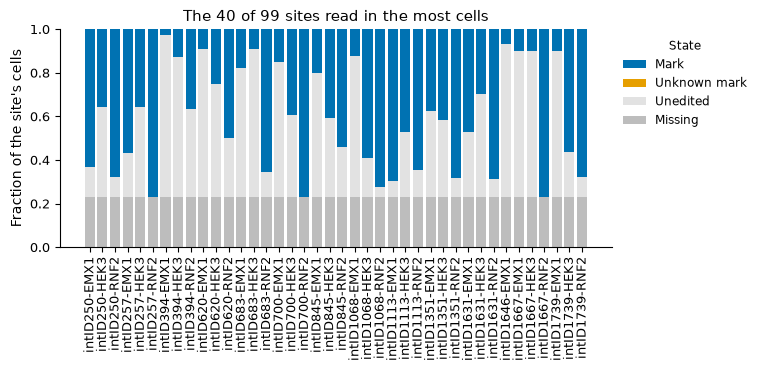

Started: 2026-11-06T15:55:53.907104Z | Wall time: 0.846 s

In [7]:
# Draw the share of cells in each state at the 40 sites read in the most cells.
ds.plots.recorder_states(alleles)

In [8]:
# Compare the kinds of site by the share of the cells reading them that hold a mark.
states = (
    ds.clones.load_alleles(alleles)
    .site_states()
    .pivot_table(
        index=["integration", "site"], columns="state", values="n_cells", observed=True
    )
)
edited = states["mark"] + states["unknown_mark"]
(edited / (edited + states["unedited"])).groupby(level="site").describe()[
    ["min", "50%", "max"]
].round(2)

,min,50%,max
site,,,
EMX1,0.00,0.23,0.91
HEK3,0.00,0.43,1.00
RNF2,0.04,0.84,1.00


Started: 2026-11-06T15:55:54.755744Z | Wall time: 0.132 s

The host's cells make up the missing 23% of each bar. The three kinds of site fill at different rates: the median RNF2 site holds a mark in 84% of the cells that read it, the median HEK3 site in 43% and the median EMX1 site in 23%.

## Export the characters for tree builders

CyteArc reads trees but does not build them. `clones.export_characters` writes the marks as a character matrix for tree builders: by default a TreeData store for Cassiopeia [@Jones_2020], or with `format="laml"` a CSV for LAML [@Mai_2024]. Cells that read no site are left out.

In [9]:
# Write the marks as a character matrix for Cassiopeia's solvers.
exported = ds.clones.export_characters(alleles, output_dir / "E7.5-R1_characters.zarr")
exported.diagnostics

{'cells': 1032, 'characters': 99, 'cellsWithSeveralAlleleRows': 0}

Started: 2026-11-06T15:55:54.890270Z | Wall time: 0.964 s

## Import the clone trees

The authors built one tree per founder clone, the descendants of one injected stem cell, and scaled its branch lengths to run from day 0 at the root to day 7.5 at the leaves, so that a node's time estimates the embryonic day of that ancestor's division; E7.5-R1 holds two such trees. `clones.import_phylogeny` reads the Newick files and joins each leaf to its cell, and `time_unit="days"` declares the unit, which the files do not state.

In [10]:
# Import the two clone trees, whose lengths are days.
phylogeny = ds.clones.import_phylogeny(
    [paths["E7.5-R1-C1.nwk.gz"], paths["E7.5-R1-C2.nwk.gz"]],
    cell_selection=cells,
    time_unit="days",
)

# Count the cells that no leaf names, and describe each tree.
diagnostics = ds.artifacts.inspect(phylogeny).diagnostics
print(diagnostics["cellsInNoTree"], "cells are in no tree")
ds.clones.load_phylogeny(phylogeny).trees

310 cells are in no tree


,tree,n_nodes,n_leaves,n_cells,root_time,earliest_leaf_time,latest_leaf_time
0,E7.5-R1-C1,1484,850,850,0.0,7.499991,7.500007
1,E7.5-R1-C2,303,182,182,0.0,7.499990,7.500000


Started: 2026-11-06T15:55:55.857445Z | Wall time: 1.545 s

The two trees hold the 1,032 donor cells, and the 310 cells in no tree are the host's.

## Cut the trees into clones

`clones.phylogeny_clones` cuts the trees at a time: each clone holds the cells that descend from one lineage alive at that time. Cut every half day from E5.0 to E7.0, and describe the clones of each cut.

In [11]:
# Cut the trees at five times, half a day apart.
cuts = {
    time: ds.clones.phylogeny_clones(phylogeny, time=time)
    for time in (5.0, 5.5, 6.0, 6.5, 7.0)
}

# Describe the clones of each cut, and count the cell types of each clone of
# two or more cells.
rows = {}
for time, clones in cuts.items():
    table = ds.clones.load_clones(clones)
    sizes = table.clones["n_cells"]
    shared = table.cells[table.cells["clone_size"] >= 2].join(
        cell_types.rename("cell_type")
    )
    rows[f"E{time}"] = {
        "Clones": len(sizes),
        "Clones of 2 or more cells": int((sizes >= 2).sum()),
        "Cells in them": int(sizes[sizes >= 2].sum()),
        "Largest clone": int(sizes.max()),
        "Cell types per clone of 2 or more cells": round(
            shared.groupby("clone", observed=True)["cell_type"].nunique().mean(), 1
        ),
    }
pd.DataFrame.from_dict(rows, orient="index")

,Clones,Clones of 2 or more cells,Cells in them,Largest clone,Cell types per clone of 2 or more cells
E5.0,48,41,1025,58,5.3
E5.5,127,112,1017,51,3.6
E6.0,289,219,962,22,2.4
E6.5,586,262,708,8,1.7
E7.0,947,78,163,4,1.3


Started: 2026-11-06T15:55:57.404285Z | Wall time: 0.867 s

The later the cut, the more clones and the fewer cell types in each: from 48 clones at E5.0, whose clones of two or more cells hold five cell types on average, to 947 at E7.0, most of them a single cell.

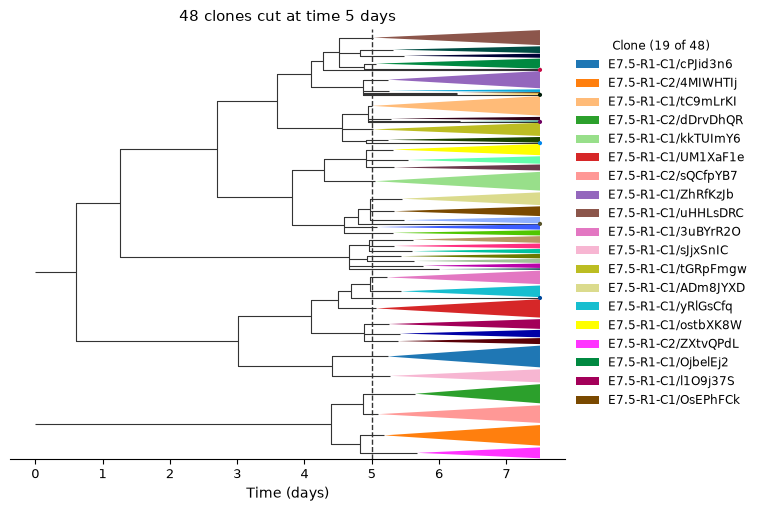

Started: 2026-11-06T15:55:58.274224Z | Wall time: 9.913 s

In [12]:
# Draw the trees with the clones of the cut at E5.0.
ds.plots.phylogeny(cuts[5.0])

Each clone of the cut at E5.0 is a wedge from its first branching to its cells at day 7.5, or a line for a clone of one cell, and the dashed line marks the cut.

## Measure coupling at each cut

`clones.coupling` measures how similarly two cell types spread over the clones, CoSpar's default measure [@Wang_2022], against the same cells with shuffled cell types, as a z-score: the coupling's distance from the mean of the shuffled couplings, in their standard deviations. Measure the eight cell types of 10 or more donor cells, leaving out three primordial germ cells and one prechordal plate cell.

In [13]:
# Keep the cell types of at least 10 donor cells.
type_sizes = cell_types[cell_types != "host"].value_counts()
measured_types = type_sizes.index[type_sizes >= 10]
ds.cells.insert("in_measured_types", cell_types.isin(measured_types), overwrite=True)
measured_cells = ds.snapshot_cell_selection("in_measured_types")

# Measure the coupling of every pair of these cell types at each cut.
couplings = {
    time: ds.clones.coupling(
        clones, group_by="cell_type", cell_selection=measured_cells
    )
    for time, clones in cuts.items()
}

# Collect each pair's z-score at each cut, and list the five pairs whose
# z-score is highest at any cut.
z_scores = pd.DataFrame(
    {
        f"E{time}": coupling.pairs.set_index(["group_1", "group_2"])["z_score"]
        for time, coupling in couplings.items()
    }
)
z_scores.loc[z_scores.max(axis=1).nlargest(5).index].round(1)

E5.0  E5.5  E6.0  E6.5  \
group_1                 group_2                                                
Extraembryonic mesoderm Hematoendothelial progenitor   0.0   1.0   3.3   3.9   
Epiblast                Primitive streak               1.6   1.1   2.7   3.6   
                        Rostral ectoderm               0.1   0.5   1.7   1.2   
Definitive endoderm     Notochord                     -1.2  -0.3   1.0  -0.4   
Nascent mesoderm        Primitive streak              -1.0  -0.3  -0.2  -1.0   

                                                      E7.0  
group_1                 group_2                             
Extraembryonic mesoderm Hematoendothelial progenitor   2.2  
Epiblast                Primitive streak               1.5  
                        Rostral ectoderm               1.0  
Definitive endoderm     Notochord                     -0.3  
Nascent mesoderm        Primitive streak               0.8

Started: 2026-11-06T15:56:08.189614Z | Wall time: 4.665 s

No pair stands out at E5.0, while at E6.0 and E6.5 the extraembryonic mesoderm couples with the hematoendothelial progenitors and the epiblast with the primitive streak, 2.7 to 3.9 standard deviations above the shuffled couplings.

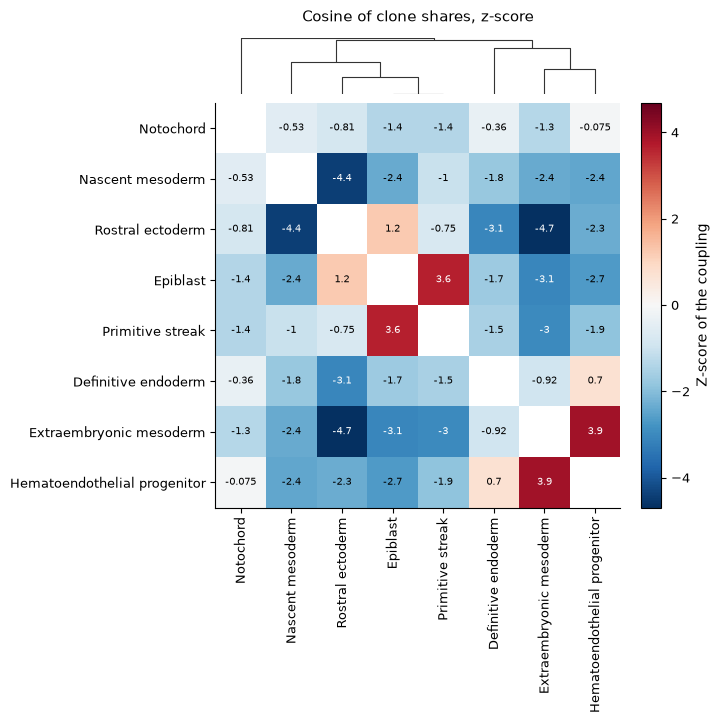

Started: 2026-11-06T15:56:12.856852Z | Wall time: 0.521 s

In [14]:
# Draw the z-scores of every pair at E6.5, with the cell types ordered by
# average linkage on their coupling.
ds.plots.clone_coupling(couplings[6.5])

At E6.5 the dendrogram joins the epiblast with the primitive streak and the rostral ectoderm, and the extraembryonic mesoderm with the hematoendothelial progenitors, which give the first blood and vessels, while the rostral ectoderm shares far fewer clones with the mesoderm than shuffled labels would. Most pairs sit below 0, because shuffled labels spread each clone over every cell type, so read the order of the z-scores more than their sign.